# Statistics 3: Discrete distributions

*Learning path: probability and statistics, part 3 of 8.* [Index](README.md) · Previous: [Probability and simulation](02-probability-and-simulation.ipynb) · Next: [Continuous distributions](04-continuous-distributions.ipynb)

Between 1875 and 1894, 196 soldiers in 10 corps of the Prussian cavalry were killed by kicks from their horses. In 1898
Ladislaus Bortkiewicz counted the deaths per corps per year and found that a single formula, with one number in it,
predicted how many corps-years would have 0, 1, 2, 3 or 4 deaths. The same formula describes typos per page, calls to a
help desk per minute and radioactive decays per second. This lesson is about such formulas: **probability
distributions** for counts.

**Who this is for.** You have done [lesson 2](02-probability-and-simulation.ipynb). You need powers, factorials and the
binomial coefficient $\binom{n}{k}$, which we recall.

**What you will be able to do afterwards:**

1. describe a random count by its distribution, and draw it as a bar chart;
2. use the binomial distribution for the number of successes in $n$ independent trials;
3. compute the expected value and variance of a distribution, and check them by simulation;
4. use the Poisson distribution for rare events, and see it as a limit of the binomial.

Plan about an hour.

## 1. Random variables and their distributions

A **random variable** is a number that comes out of a random experiment: the sum of two dice, the number of heads in
10 tosses, the number of deaths in a corps in a year. Its **distribution** lists the possible values $k$ with their
probabilities $P(X = k)$, which add up to 1.

Toss three coins and let $X$ be the number of heads. Of the 8 equally likely outcomes, one has no heads, three have
one (HTT, THT, TTH), three have two and one has three:

1

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

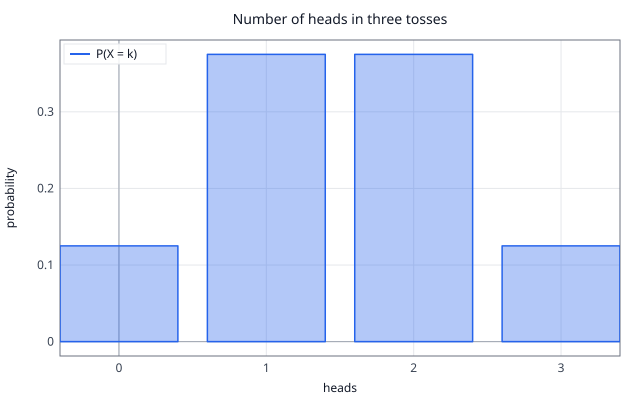

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
k = [0 1 2 3];
P = [1 3 3 1]/8;
sum(P)
p = bar(k, P);
labels(title(legend(p, "P(X = k)"), "Number of heads in three tosses"), "heads", "probability")

The numbers $1, 3, 3, 1$ are $\binom{3}{0}, \binom{3}{1}, \binom{3}{2}, \binom{3}{3}$: the number of ways to choose
which tosses are heads. `binomial(n, k)` computes them.

**Try this.** List the probabilities for four tosses using `binomial(4, 0)` to `binomial(4, 4)`, divided by 16.

## 2. The binomial distribution

A basketball player makes 30% of her three-point shots, independently of each other. In 10 shots, what is the chance
of exactly 3 baskets? One particular order (3 baskets, then 7 misses) has probability $0.3^3\,0.7^7$, and there are
$\binom{10}{3}$ orders, so

$$P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}, \qquad k = 0, 1, \ldots, n.$$

This is the **binomial distribution** with $n$ trials and success probability $p$. `binopdf(k, n, p)` gives it, for
one value of $k$ or a whole list:

66706983/250000000

> Binomial probability P(X = k) = C(n, k) p^k (1 − p)^(n − k): exactly k successes in n = 10 independent trials.

0.266827932

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

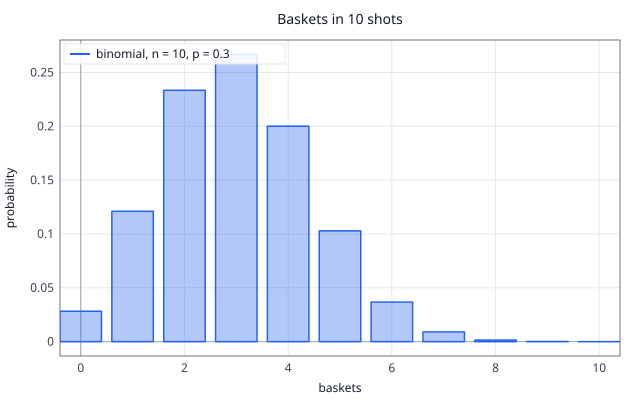

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
binopdf(3, 10, 3/10)
eval(binopdf(3, 10, 3/10))
k = [0 1 2 3 4 5 6 7 8 9 10];
P = binopdf(k, 10, 3/10);
p = bar(k, P);
labels(title(legend(p, "binomial, n = 10, p = 0.3"), "Baskets in 10 shots"), "baskets", "probability")

Three baskets is the most likely count, with probability 0.267. The **cumulative** probability $P(X \le k)$ adds the
bars up to $k$; `binocdf` gives it. The chance of at most one basket, and of five or more:

In [3]:
eval(binocdf(1, 10, 3/10))
eval(1 - binocdf(4, 10, 3/10))

0.1493083459

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.1502683326

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** A multiple-choice test has 20 questions with 4 choices each. Guessing at random, what is the probability
of 10 or more right? (Use `1 - binocdf(9, 20, 1/4)`.)

## 3. Expected value and variance

The **expected value** (or mean) of a distribution is the average of its values, weighted by their probabilities:
$E[X] = \sum_k k\,P(X = k)$. With the values in a row and the probabilities in another, this sum is the product of a
row and a column, $k\,P^T$:

In [4]:
k*P'
sum(j*binopdf(j, 10, 3/10), j, 0, 10)

3
3

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

The player expects 3 baskets in 10 shots, as common sense says: $E[X] = np$. The **variance** is the expected squared
distance from the mean, $\operatorname{Var}(X) = \sum_k (k - \mu)^2 P(X = k)$, and for the binomial it equals
$np(1 - p)$:

In [5]:
sum((j - 3)^2*binopdf(j, 10, 3/10), j, 0, 10)
10*(3/10)*(7/10)

21/10

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

21/10

The expected value is a long-run average. Simulate 2000 seasons of 10 shots with `randbin(n, p, count)` and compare
the sample mean and variance with $3$ and $2.1$:

In [6]:
seed(4);
x = randbin(10, 0.3, 2000);
tally(x)
eval(mean(x))
eval(var(x))

[ 0,   1,   2,   3,   4,   5,  6,  7, 8;
 63, 260, 469, 547, 405, 171, 62, 19, 4]

> tally: the first row lists the distinct values, the second how often each occurs.

2.9255

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.05897923961981

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The sample mean is 2.93 and the sample variance 2.06, close to 3 and 2.1. The table also shows how the simulated
counts follow the bars: 3 baskets came up 547 times, against $2000 \times 0.267 = 534$ expected.

**Try this.** For a fair die, $E[X] = (1 + 2 + \cdots + 6)/6$. Compute it with `[1 2 3 4 5 6]*[1 1 1 1 1 1]'/6`. Can
the expected value itself ever come up?

## 4. The Poisson distribution and the horse kicks

When there are many chances for something rare to happen, such as many soldiers each with a tiny chance of a fatal
kick, the count follows the **Poisson distribution** with mean $\lambda$:

$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}, \qquad k = 0, 1, 2, \ldots$$

Both its mean and its variance are $\lambda$. Here are Bortkiewicz's data: 200 corps-years, and how many of them had
0, 1, 2, 3 and 4 deaths.

In [7]:
k = [0 1 2 3 4];
years = [109 65 22 3 1];
sum(years)
lambda = k*years'/200

200

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

61/100

On average 0.61 deaths per corps-year. Multiply the Poisson probabilities by 200 to get the predicted number of
corps-years with each count:

[108.7, 66.3, 20.2, 4.1, 0.6]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

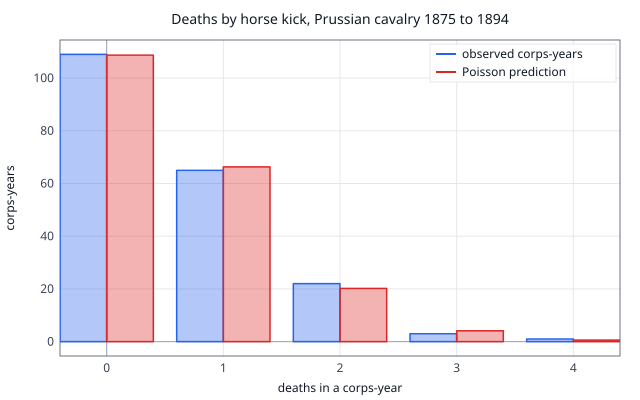

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
predicted = round(200*eval(poisspdf(k, 61/100)), 1)
p = bar(k - 0.2, years, 0.4);
p = show(p, bar(k + 0.2, predicted, 0.4));
p = legend(p, "observed corps-years", "Poisson prediction");
labels(title(p, "Deaths by horse kick, Prussian cavalry 1875 to 1894"), "deaths in a corps-year", "corps-years")

The agreement is remarkable: 109 against 108.7, 65 against 66.3, 22 against 20.2. One number, the mean, fixes the whole
distribution. ([Lesson 7](07-hypothesis-tests.ipynb) measures "remarkable" with the chi-square test.)

**Try this.** A help desk gets on average 2 calls a minute. What is the probability of 5 or more calls in one minute?
(Use `1 - poisscdf(4, 2)`.)

## 5. Poisson as a limit of the binomial

Take $n = 1000$ trials with $p = 1/500$: the binomial has mean $np = 2$. The Poisson with $\lambda = 2$ gives nearly the
same probabilities:

[0.1351, 0.2707, 0.2709, 0.1806, 0.0902, 0.036, 0.012, 0.0034, 0.0008]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

[0.1353, 0.2707, 0.2707, 0.1804, 0.0902, 0.0361, 0.012, 0.0034, 0.0009]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

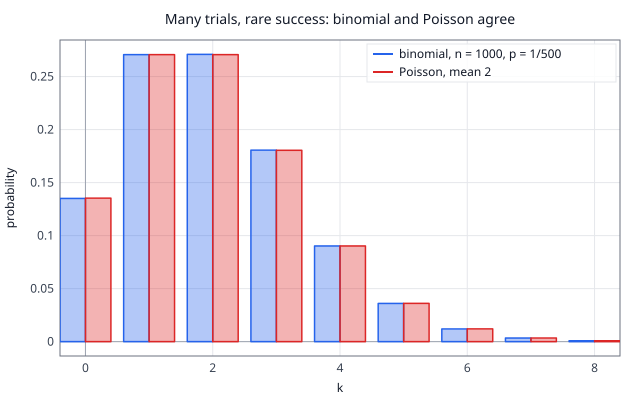

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
k = [0 1 2 3 4 5 6 7 8];
B = eval(binopdf(k, 1000, 1/500));
Q = eval(poisspdf(k, 2));
round(B, 4)
round(Q, 4)
p = bar(k - 0.2, B, 0.4);
p = show(p, bar(k + 0.2, Q, 0.4));
p = legend(p, "binomial, n = 1000, p = 1/500", "Poisson, mean 2");
labels(title(p, "Many trials, rare success: binomial and Poisson agree"), "k", "probability")

As $n$ grows with $np = \lambda$ fixed, $\binom{n}{k}p^k(1 - p)^{n - k} \to \lambda^k e^{-\lambda}/k!$. You can check
the key step, $(1 - \lambda/n)^n \to e^{-\lambda}$, with a limit:

In [10]:
limit((1 - 2/n)^n, n, inf)

1/exp(2)

> `limit`: Limit of f as x approaches a, from both sides or one side.

This is why the Poisson fits horse kicks: each soldier is one of many trials with a tiny probability.

**Try this.** Compare `binopdf(2, 20, 1/10)` with `poisspdf(2, 2)`. With only 20 trials, is the approximation still
good?

## Summary

* A random variable's distribution lists its values with probabilities that add up to 1; a bar chart shows it.
* Binomial: successes in $n$ independent trials, $P(X = k) = \binom{n}{k}p^k(1 - p)^{n - k}$, mean $np$, variance
  $np(1 - p)$.
* Expected value $E[X] = \sum k\,P(X = k)$, a long-run average; variance $\sum (k - \mu)^2 P(X = k)$.
* Poisson: rare events, $P(X = k) = \lambda^k e^{-\lambda}/k!$, mean and variance $\lambda$; the limit of the binomial
  when $n$ is large and $np = \lambda$.

Next: [continuous distributions](04-continuous-distributions.ipynb), where sums become integrals.

## Exercises

1. **Families.** In a family with 4 children, each a boy or girl with probability 1/2, what is the probability of
   exactly 2 girls? Of at least one girl?
2. **Quality control.** A machine makes 2% defective parts. In a box of 50, find the probability of no defects, with
   the binomial and with the Poisson approximation.
3. **Variance by simulation.** Simulate `randpois(3, 2000)` and check that the mean and the variance are both near 3.
4. **A fair game?** You pay 1 to roll a die and win 4 if it shows a six. What is your expected gain per game?
5. **Overbooking.** An airline sells 105 tickets for 100 seats; each passenger shows up with probability 0.93,
   independently. What is the probability that more than 100 show up?

## Hints and answers

* **Section 1, Try this.** $1/16, 4/16, 6/16, 4/16, 1/16$.
* **Section 2, Try this.** About 0.014: guessing rarely gets half right.
* **Section 3, Try this.** $E[X] = 7/2$, which no single roll can show: an expected value need not be a possible value.
* **Section 4, Try this.** About 0.053.
* **Section 5, Try this.** 0.285 against 0.271: still within about 5%.
* **Exercise 1.** $\binom{4}{2}/16 = 3/8$; $1 - 1/16 = 15/16$.
* **Exercise 2.** Binomial $0.98^{50} \approx 0.364$; Poisson $e^{-1} \approx 0.368$.
* **Exercise 3.** Both come out near 3; differences of a few tenths are ordinary for 2000 values.
* **Exercise 4.** $4 \cdot \tfrac16 - 1 = -1/3$: you lose a third per game on average.
* **Exercise 5.** `1 - binocdf(100, 105, 0.93)` $\approx 0.134$: about one flight in seven is overbooked.

## Sources

1. L. von Bortkiewicz, *Das Gesetz der kleinen Zahlen*, Teubner, Leipzig (1898) (the horse-kick data).
2. W. Feller, *An Introduction to Probability Theory and Its Applications*, vol. 1, 3rd ed., Wiley (1968), chapter 6.
3. S. D. Poisson, *Recherches sur la probabilité des jugements en matière criminelle et en matière civile*, Bachelier,
   Paris (1837).
4. D. Freedman, R. Pisani and R. Purves, *Statistics*, 4th ed., Norton (2007), chapters 15 and 16.